In [1]:
install.packages("readr")
library(readr)

data=read_csv("data2.csv")
head(data)
str(data)

Warning message:
“unable to access index for repository https://cran.r-project.org/src/contrib:
  URL 'https://cran.r-project.org/src/contrib/PACKAGES' açılamıyor”
Warning message:
“package ‘readr’ is not available for this version of R

A version of this package for your version of R might be available elsewhere,
see the ideas at
https://cran.r-project.org/doc/manuals/r-devel/R-admin.html#Installing-packages”
Warning message:
“unable to access index for repository https://cran.r-project.org/bin/macosx/big-sur-arm64/contrib/4.4:
  URL 'https://cran.r-project.org/bin/macosx/big-sur-arm64/contrib/4.4/PACKAGES' açılamıyor”
Rows: 124 Columns: 2
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (2): Year, Average_Fahrenheit_Temperature

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Year,Average_Fahrenheit_Temperature
<dbl>,<dbl>
1900,53.9
1901,53.5
1902,52.1
1903,50.6
1904,51.8
1905,51.7


spc_tbl_ [124 × 2] (S3: spec_tbl_df/tbl_df/tbl/data.frame)
 $ Year                          : num [1:124] 1900 1901 1902 1903 1904 ...
 $ Average_Fahrenheit_Temperature: num [1:124] 53.9 53.5 52.1 50.6 51.8 51.7 51.2 52.4 50.1 51.8 ...
 - attr(*, "spec")=
  .. cols(
  ..   Year = col_double(),
  ..   Average_Fahrenheit_Temperature = col_double()
  .. )
 - attr(*, "problems")=<externalptr> 


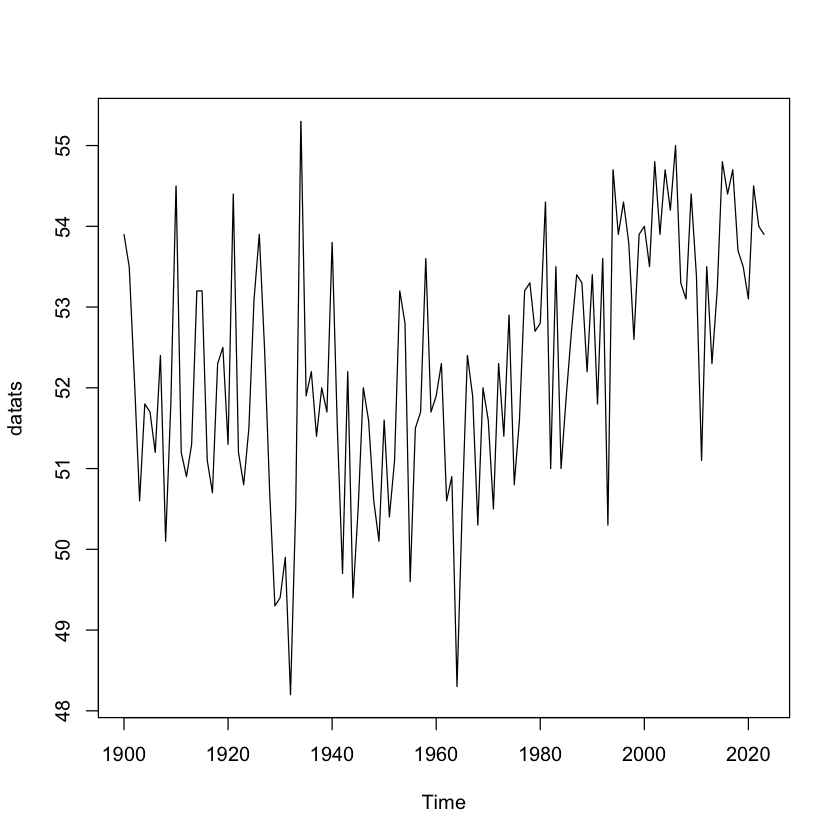

In [2]:
datats=ts(data$Average_Fahrenheit_Temperature,start=c(1900))
# Plot the time series
plot.ts(datats)

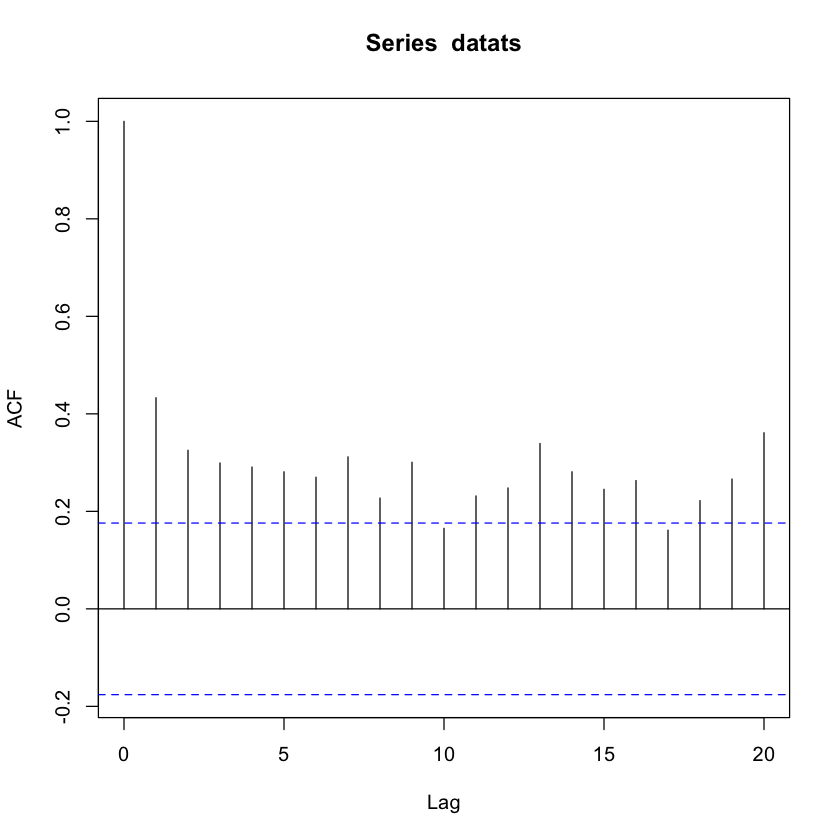

In [30]:
acf(datats)

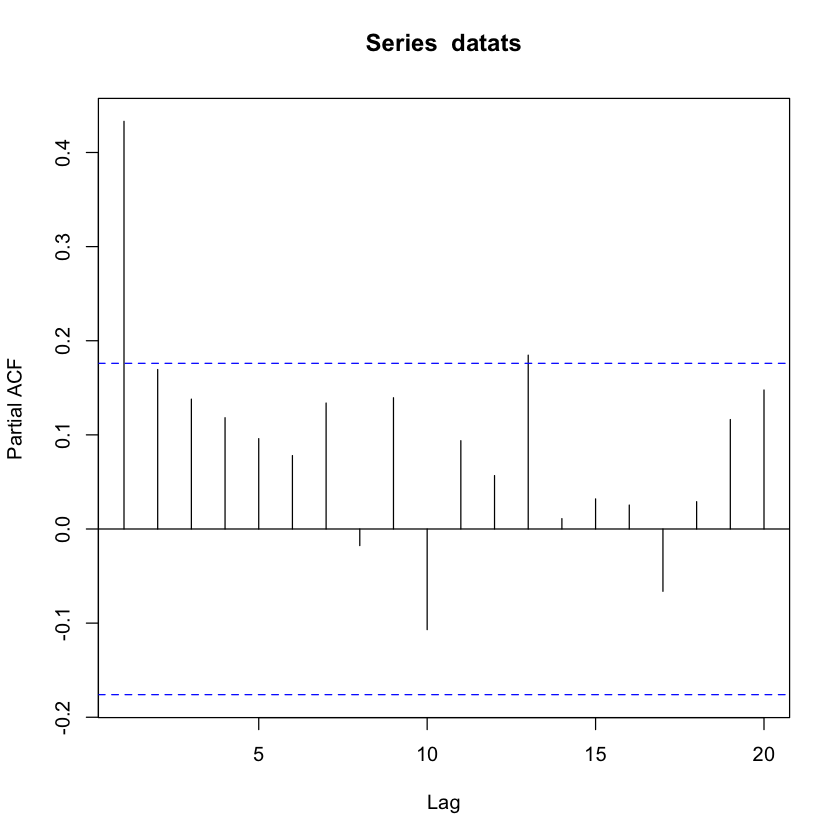

In [31]:
pacf(datats)

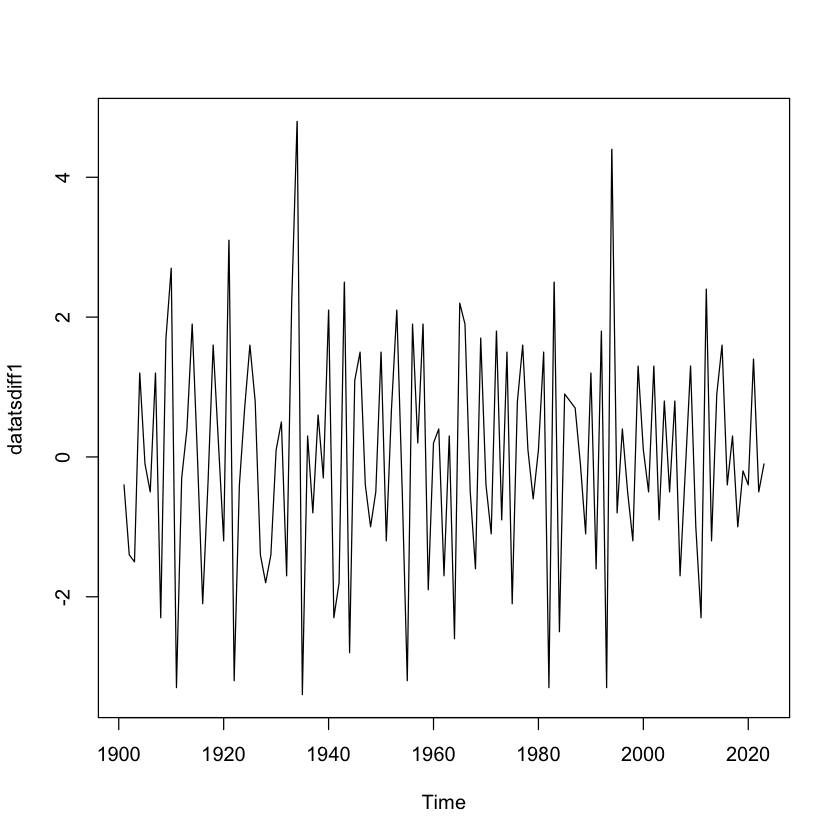

In [3]:
datatsdiff1=diff(datats,differences=1)
plot.ts(datatsdiff1)

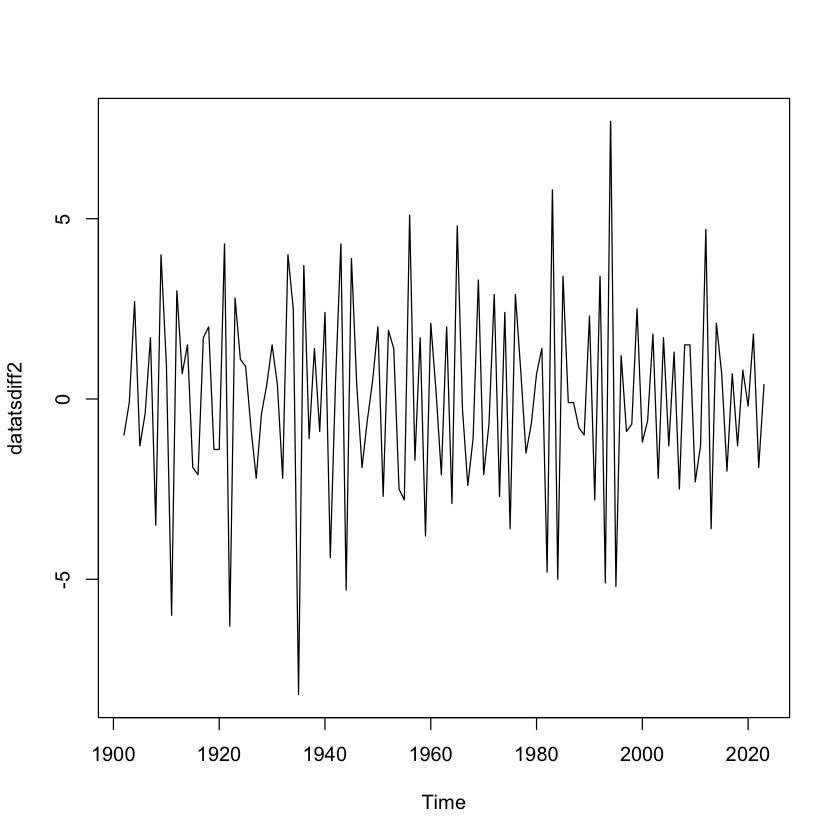

In [4]:
datatsdiff2=diff(datats,differences=2)
plot.ts(datatsdiff2)

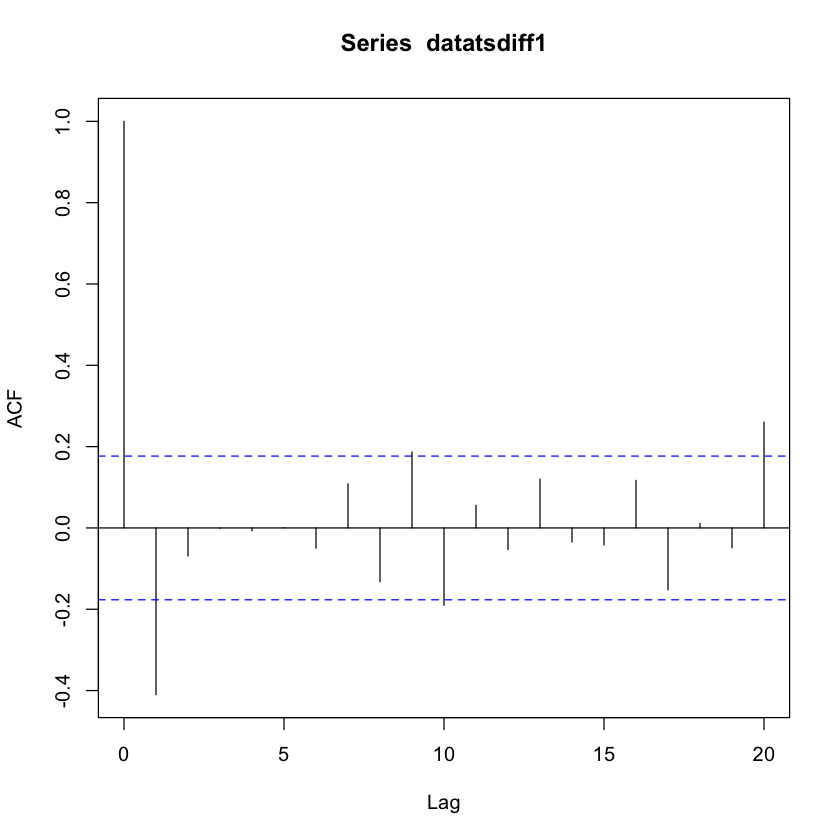

In [5]:
acf(datatsdiff1,lag.max=20)

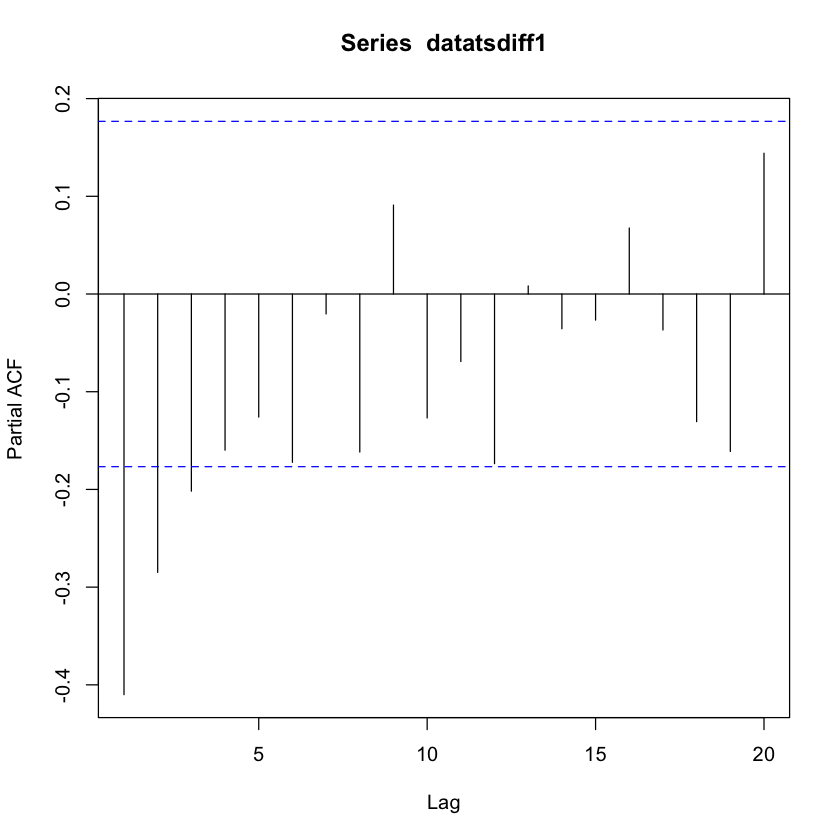

In [6]:
pacf(datatsdiff1,lag.max=20)

In [7]:
arima1=arima(datats,order=c(3,1,0))
arima1


Call:
arima(x = datats, order = c(3, 1, 0))

Coefficients:
          ar1      ar2      ar3
      -0.5879  -0.3993  -0.2108
s.e.   0.0884   0.0970   0.0887

sigma^2 estimated as 1.913:  log likelihood = -214.66,  aic = 437.32

In [8]:
library(lmtest)


Zorunlu paket yükleniyor: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




In [9]:
coeftest(arima1)


z test of coefficients:

     Estimate Std. Error z value  Pr(>|z|)    
ar1 -0.587924   0.088369 -6.6530 2.871e-11 ***
ar2 -0.399324   0.096957 -4.1186 3.812e-05 ***
ar3 -0.210832   0.088666 -2.3778   0.01741 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


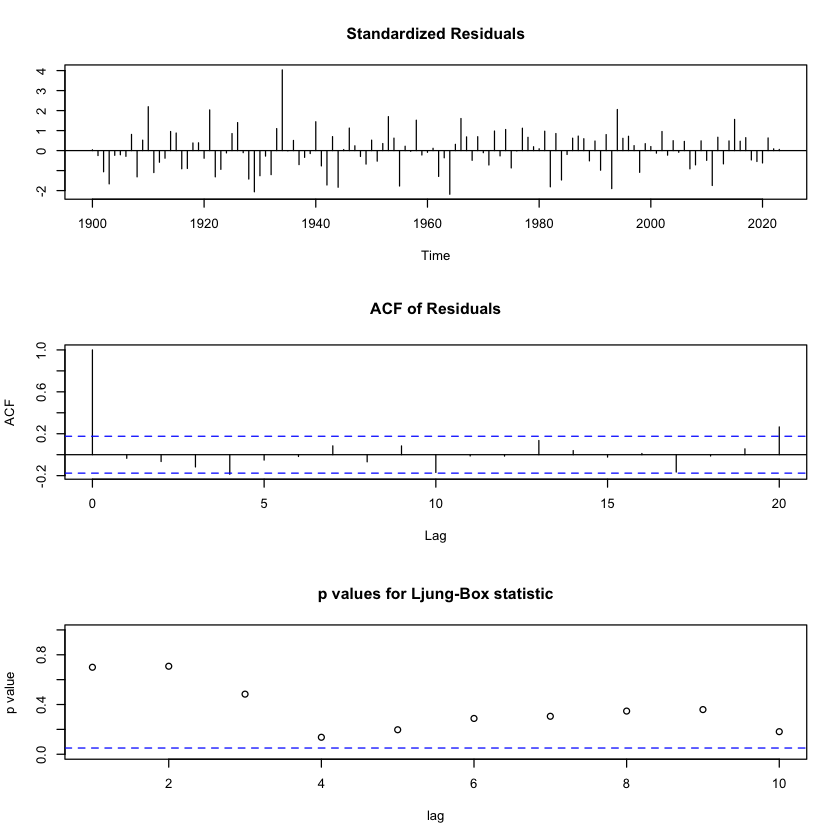

In [10]:
tsdiag(arima1)

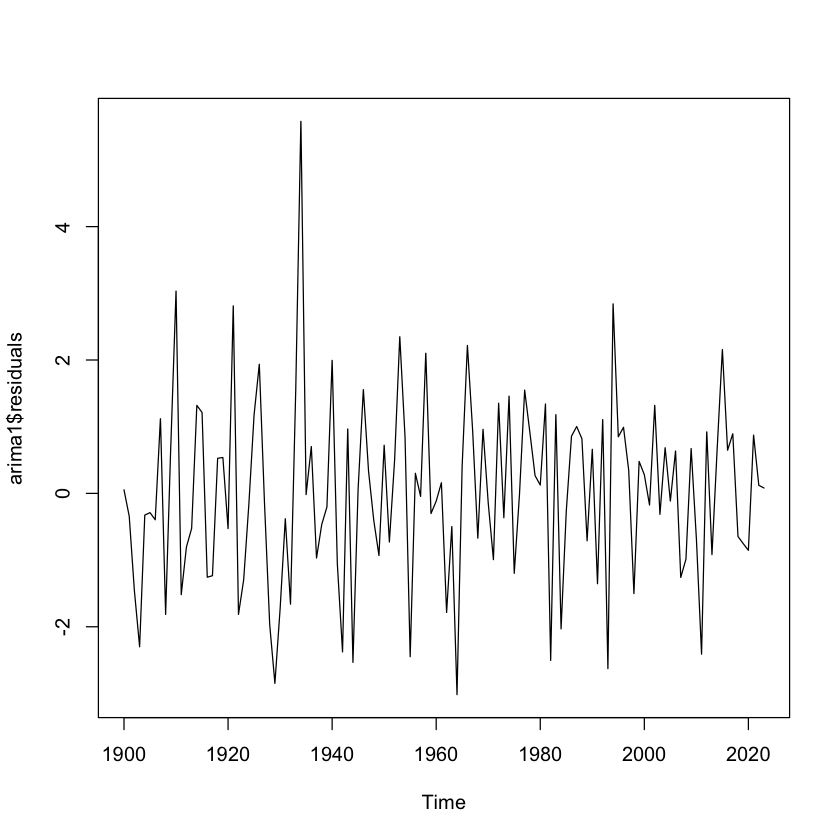

In [11]:
plot.ts(arima1$residuals)

In [12]:
shapiro.test(arima1$residuals)


	Shapiro-Wilk normality test

data:  arima1$residuals
W = 0.97819, p-value = 0.04219


In [13]:
arima2=arima(datats,order=c(0,1,2))
arima2


Call:
arima(x = datats, order = c(0, 1, 2))

Coefficients:
          ma1      ma2
      -0.7370  -0.1328
s.e.   0.0893   0.0856

sigma^2 estimated as 1.685:  log likelihood = -207.27,  aic = 420.54

In [14]:
coeftest(arima2)


z test of coefficients:

     Estimate Std. Error z value Pr(>|z|)    
ma1 -0.736967   0.089281 -8.2545   <2e-16 ***
ma2 -0.132825   0.085640 -1.5510   0.1209    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


1.55 z valueden dolayı ma2 anlamsızdır.

In [15]:
arima3=arima(datats,order=c(3,1,2))
arima3


Call:
arima(x = datats, order = c(3, 1, 2))

Coefficients:
          ar1     ar2     ar3     ma1      ma2
      -0.7645  0.1148  0.0216  0.0421  -0.8292
s.e.   0.1252  0.1366  0.1000  0.0873   0.0759

sigma^2 estimated as 1.663:  log likelihood = -206.5,  aic = 425

In [16]:
coeftest(arima3)


z test of coefficients:

     Estimate Std. Error  z value  Pr(>|z|)    
ar1 -0.764550   0.125160  -6.1086 1.005e-09 ***
ar2  0.114763   0.136572   0.8403    0.4007    
ar3  0.021637   0.100009   0.2164    0.8287    
ma1  0.042072   0.087312   0.4819    0.6299    
ma2 -0.829202   0.075858 -10.9309 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


In [17]:
arima4=arima(datats,order=c(2,1,2))
coeftest(arima4)


z test of coefficients:

     Estimate Std. Error z value Pr(>|z|)    
ar1  1.158464   0.098175  11.800  < 2e-16 ***
ar2 -0.243397   0.099956  -2.435  0.01489 *  
ma1 -1.927168   0.048130 -40.041  < 2e-16 ***
ma2  0.945083   0.047575  19.865  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


In [18]:
arima4


Call:
arima(x = datats, order = c(2, 1, 2))

Coefficients:
         ar1      ar2      ma1     ma2
      1.1585  -0.2434  -1.9272  0.9451
s.e.  0.0982   0.1000   0.0481  0.0476

sigma^2 estimated as 1.61:  log likelihood = -205.15,  aic = 420.31

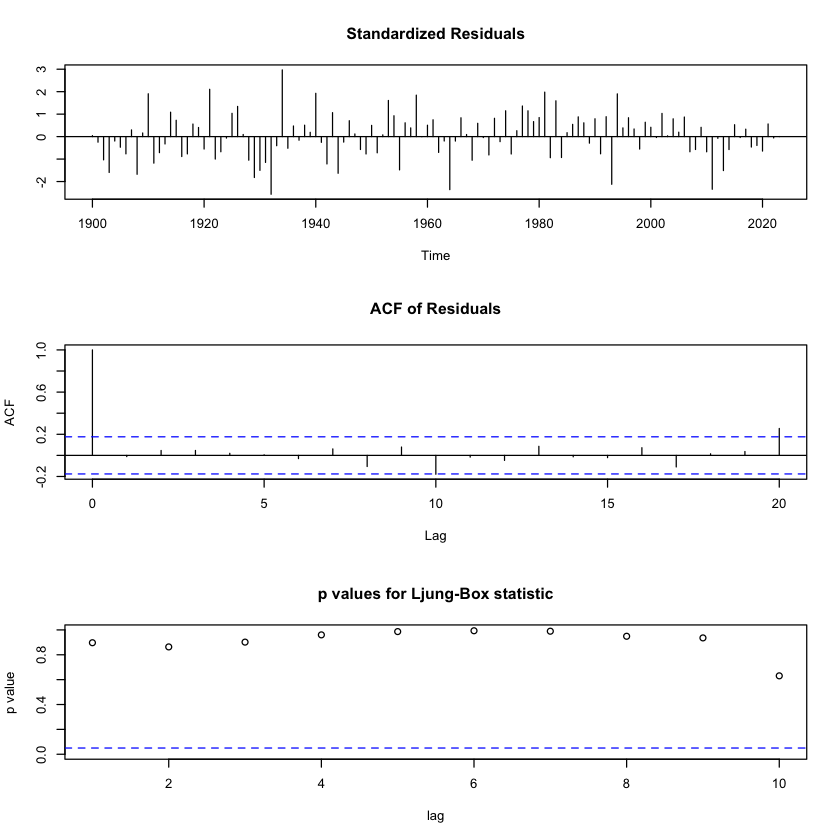

In [19]:
tsdiag(arima4)

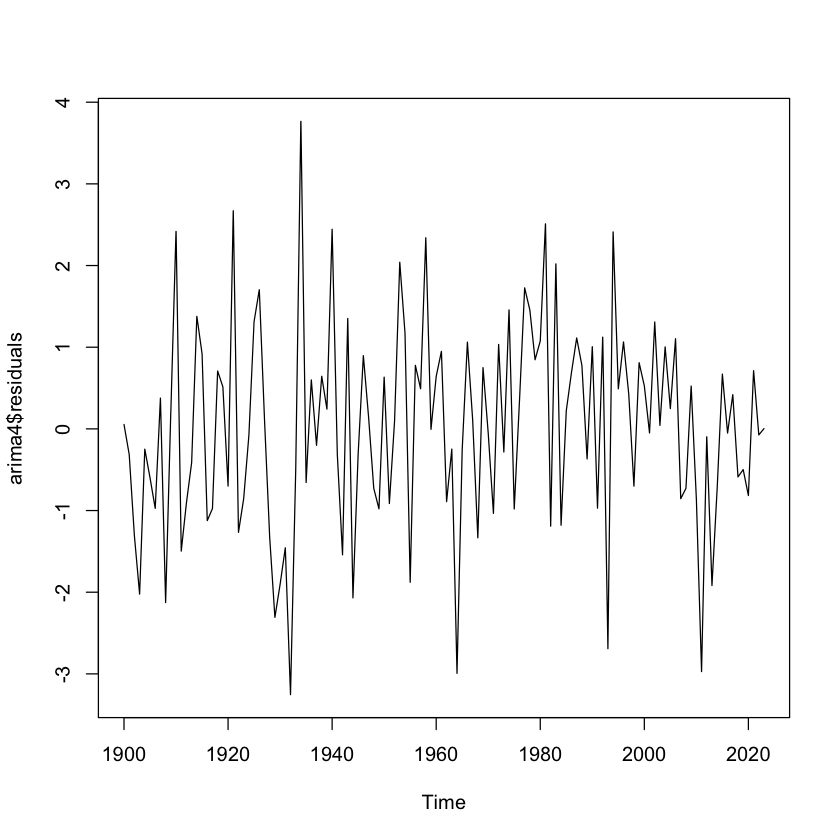

In [20]:
plot.ts(arima4$residuals)

In [21]:
shapiro.test(arima4$residuals)


	Shapiro-Wilk normality test

data:  arima4$residuals
W = 0.99315, p-value = 0.8085


In [22]:
Box.test(arima4$residuals,lag=6)


	Box-Pierce test

data:  arima4$residuals
X-squared = 0.72251, df = 6, p-value = 0.994


In [23]:
Box.test(arima4$residuals,lag=12)


	Box-Pierce test

data:  arima4$residuals
X-squared = 7.6167, df = 12, p-value = 0.8143


In [24]:
Box.test(arima4$residuals,lag=18)


	Box-Pierce test

data:  arima4$residuals
X-squared = 10.784, df = 18, p-value = 0.9033


In [25]:
Box.test(arima4$residuals,lag=24)


	Box-Pierce test

data:  arima4$residuals
X-squared = 19.619, df = 24, p-value = 0.7182


In [26]:
library(forecast)

Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 



In [27]:
forecastdata=forecast(arima4,h=10)
forecastdata

     Point Forecast    Lo 80    Hi 80    Lo 95    Hi 95
2024       53.82919 52.20319 55.45520 51.34243 56.31595
2025       53.77472 52.10577 55.44367 51.22227 56.32716
2026       53.72885 52.05847 55.39922 51.17422 56.28347
2027       53.68896 52.01850 55.35943 51.13421 56.24372
2028       53.65392 51.98315 55.32470 51.09869 56.20916
2029       53.62304 51.95109 55.29499 51.06601 56.18007
2030       53.59579 51.92121 55.27037 51.03474 56.15684
2031       53.57174 51.89268 55.25080 51.00384 56.13965
2032       53.55052 51.86492 55.23611 50.97262 56.12841
2033       53.53178 51.83752 55.22603 50.94064 56.12292

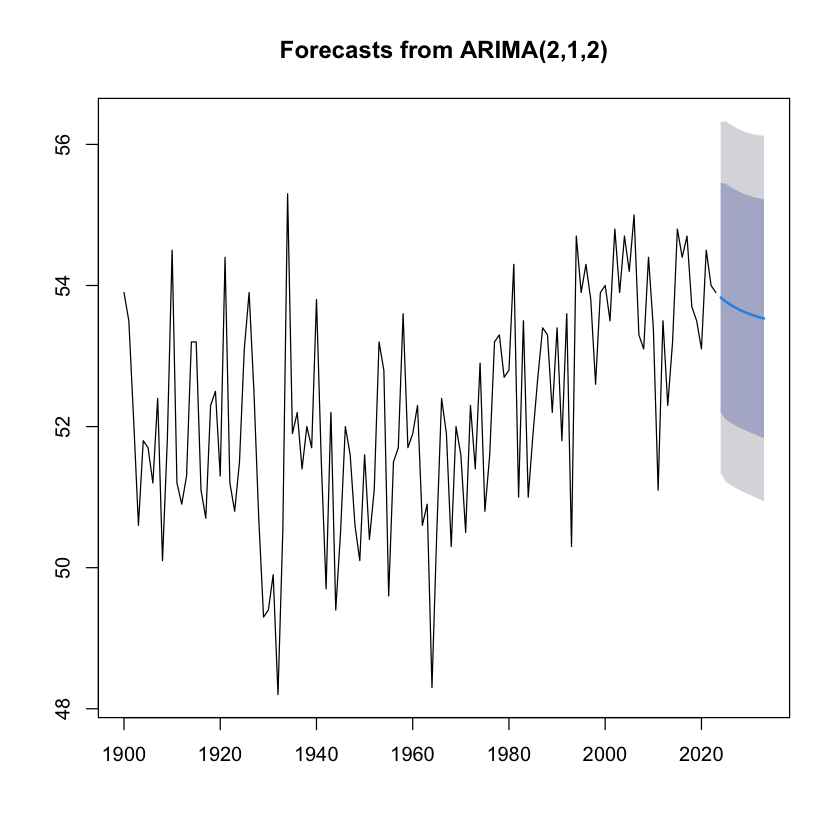

In [28]:
plot(forecastdata)

In [29]:
library(forecast)
auto.arima(datats)

Series: datats 
ARIMA(0,1,2) 

Coefficients:
          ma1      ma2
      -0.7370  -0.1328
s.e.   0.0893   0.0856

sigma^2 = 1.713:  log likelihood = -207.27
AIC=420.54   AICc=420.74   BIC=428.98